# Data Readiness Pipeline: Hotel Bookings

This notebook covers the detailed work for the `hotel_bookings.csv` file, including loading, cleaning, stakeholder framing, and
exploratory data analysis (EDA).

## How to run
Run all cells top to bottom (`Run All`).

## Dependencies
- Python 3.10+
- `pandas >= 2.0`, `numpy`, `matplotlib`

```
pip install pandas numpy matplotlib
```

## File locations
| File | Description |
|---|---|
| `hotel_bookings.csv` | Raw input file. Must sit in the same folder as this notebook (or update `RAW_DATA_PATH` below). |
| `hotel_bookings_clean.csv` | **Output.** Cleaned dataset written after the cleaning section. |
| `cleaning_log.csv` | **Output.** Row/column counts before and after each cleaning step, for auditability. |

## Run order
1. Setup
2. Load raw data
3. Initial profiling
4. Data cleaning (duplicates, missing values, category standardisation, dtypes, implausible values, feature engineering)
5. Validation of the cleaned dataset
6. Save cleaned outputs
7. Stakeholder problem and success criteria
8. Exploratory Data Analysis (on the cleaned data)


## Random seeds
No random sampling or splitting happens in this notebook, so no seed is
required here.

**1. Setup**

In [339]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110

RAW_DATA_PATH = "hotel_bookings.csv"
CLEAN_DATA_PATH = "hotel_bookings_clean.csv"
CLEANING_LOG_PATH = "cleaning_log.csv"

cleaning_log = []

def log_cleaning_step(issue, evidence, action, justification, df_before, df_after):
    cleaning_log.append({
        "issue": issue,
        "evidence": evidence,
        "action": action,
        "justification": justification,
        "rows_before": df_before.shape[0],
        "cols_before": df_before.shape[1],
        "rows_after": df_after.shape[0],
        "cols_after": df_after.shape[1],
        "rows_removed": df_before.shape[0] - df_after.shape[0],
        "cols_removed": df_before.shape[1] - df_after.shape[1],
    })

**2. Load raw data**

In [340]:
df = pd.read_csv(RAW_DATA_PATH, low_memory=False)
print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()


Loaded 119,987 rows x 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,City Hotel,1,29,2016,February,6,5,6,14,1,0.0,0,BB,BRA,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,70.91,0,0,Canceled,2016-01-15
1,Resort Hotel,0,312,2017,March,10,5,2,5,2,0.0,0,HB,DEU,Groups,TA/TO,0,0,0,A,A,0,No Deposit,298.0,NaN,0,Transient-Party,56.00,0,0,Check-Out,2017-03-12
2,Resort Hotel,0,19,2016,February,9,27,0,1,2,0.0,0,BB,PRT,Complementary,TA/TO,0,0,0,A,F,0,No Deposit,5.0,NaN,0,Transient,0.00,0,0,Check-Out,2016-02-28
3,City Hotel,1,159,2017,July,27,8,1,1,2,0.0,0,SC,IRL,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,89.10,0,0,Canceled,2017-03-01
4,City Hotel,0,89,2016,June,27,26,2,3,2,0.0,0,BB,FRA,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,107.10,0,3,Check-Out,2016-07-01


#### This is done so that we can keep a track of what cleaning log does

In [341]:
df_before = df.copy()
df_before.shape

(119987, 32)

**3. Descibing the existing data**

In [342]:
df.shape
df.head()
df.info()
df.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119987 entries, 0 to 119986
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119987 non-null  object 
 1   is_canceled                     119987 non-null  int64  
 2   lead_time                       119987 non-null  int64  
 3   arrival_date_year               119987 non-null  int64  
 4   arrival_date_month              119987 non-null  object 
 5   arrival_date_week_number        119987 non-null  int64  
 6   arrival_date_day_of_month       119987 non-null  int64  
 7   stays_in_weekend_nights         119987 non-null  int64  
 8   stays_in_week_nights            119987 non-null  int64  
 9   adults                          119987 non-null  int64  
 10  children                        119805 non-null  float64
 11  babies                          119987 non-null  int64  
 12  meal            

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,119987,119987.000000,119987.000000,119987.000000,119987,119987.000000,119987.000000,119987.000000,119987.000000,119987.000000,119805.000000,119987.000000,119849,119359,119858,119823,119987.000000,119987.000000,119987.000000,119987,119987,119987.000000,119987,103446.000000,6825.000000,119987.000000,119833,119987.000000,119987.000000,119987.000000,119987,119987
unique,4,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,177,14,9,NaN,NaN,NaN,10,12,NaN,3,NaN,NaN,NaN,8,NaN,NaN,NaN,6,1686
top,City Hotel,NaN,NaN,NaN,August,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BB,PRT,Online TA,TA/TO,NaN,NaN,NaN,A,A,NaN,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-10-21
freq,79570,NaN,NaN,NaN,13954,NaN,NaN,NaN,NaN,NaN,NaN,NaN,92498,48778,56673,98049,NaN,NaN,NaN,86442,74418,NaN,105162,NaN,NaN,NaN,89824,NaN,NaN,NaN,75425,1443
mean,NaN,0.370440,106.105478,2016.156450,NaN,27.166810,15.799395,0.927634,2.499912,1.856284,0.103927,0.007959,NaN,NaN,NaN,NaN,0.031928,0.086968,0.136906,NaN,NaN,0.221074,NaN,86.741537,189.475604,2.319201,NaN,102.801864,0.062482,0.571195,NaN,NaN
std,NaN,0.482925,114.786587,0.707567,NaN,13.605147,8.782317,0.998560,1.907699,0.578709,0.398603,0.097448,NaN,NaN,NaN,NaN,0.175810,0.842424,1.495620,NaN,NaN,0.652046,NaN,110.810466,131.735152,17.580735,NaN,55.962944,0.245211,0.792577,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,NaN,0.000000,NaN,1.000000,6.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,18.000000,2016.000000,NaN,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,NaN,0.000000,NaN,9.000000,62.000000,0.000000,NaN,69.360000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,69.000000,2016.000000,NaN,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,NaN,0.000000,NaN,14.000000,179.000000,0.000000,NaN,95.000000,0.000000,0.000000,NaN,NaN
75%,NaN,1.000000,161.000000,2017.000000,NaN,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,NaN,0.000000,NaN,229.000000,270.000000,0.000000,NaN,126.000000,0.000000,1.000000,NaN,NaN


In [343]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 119987
Columns: 32


**4. Analyzing missing data**

In [344]:
missing = df.isnull().sum()
print(missing)

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                             182
babies                                 0
meal                                 138
country                              628
market_segment                       129
distribution_channel                 164
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16541
company         

In [345]:
missing_table = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": df.isnull().mean() * 100
})

print(missing_table)

                                missing_count  missing_percentage
hotel                                       0            0.000000
is_canceled                                 0            0.000000
lead_time                                   0            0.000000
arrival_date_year                           0            0.000000
arrival_date_month                          0            0.000000
arrival_date_week_number                    0            0.000000
arrival_date_day_of_month                   0            0.000000
stays_in_weekend_nights                     0            0.000000
stays_in_week_nights                        0            0.000000
adults                                      0            0.000000
children                                  182            0.151683
babies                                      0            0.000000
meal                                      138            0.115012
country                                   628            0.523390
market_seg

In [346]:
duplicate_rows = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_rows}")

Number of duplicate rows: 31328


In [347]:
print(f"DataFrame shape before dropping duplicates: {df.shape}")

n_dupes = df.duplicated().sum()
evidence = f"{n_dupes:,} exact duplicate rows found ({n_dupes / len(df):.1%} of data); no booking ID column to disambiguate"
print(evidence)
df = df.drop_duplicates()
print(f"DataFrame shape after dropping duplicates: {df.shape}")

log_cleaning_step(
    issue="Duplicate rows",
    evidence=evidence,
    action="Dropped exact duplicate rows",
    justification="A duplicated row cannot be distinguished from a genuine repeat booking without a booking ID; keeping them would bias class balance and grouped statistics",
    df_before=df_before, df_after=df,
)

DataFrame shape before dropping duplicates: (119987, 32)
31,328 exact duplicate rows found (26.1% of data); no booking ID column to disambiguate
DataFrame shape after dropping duplicates: (88659, 32)


 **5. Handling Missing Values**

Based on our earlier analysis of missing values, we'll implement the following strategy:

1.  **Drop 'company' column**: It has over 94% missing values, making it largely uninformative.
2.  **Fill 'children' with 0**: Missing values likely indicate no children were part of the booking.
3.  **Fill 'agent' with 0**: Missing values for agent typically mean no travel agent was involved.
4.  **Fill other categorical missing values with 'Unknown'**: For columns like `meal`, `country`, `market_segment`, `distribution_channel`, and `customer_type`, filling with 'Unknown' is a safe approach to acknowledge missing data without altering distributions or removing rows.

In [348]:
df_before = df.copy()

evidence = (
    f"company: {df['company'].isna().mean():.1%} missing | "
    f"agent: {df['agent'].isna().mean():.1%} missing | "
    f"children: {df['children'].isna().mean():.1%} missing | "
    f"meal/country/market_segment/distribution_channel/customer_type: <1% missing each"
)
print(evidence)

company: 94.0% missing | agent: 14.1% missing | children: 0.2% missing | meal/country/market_segment/distribution_channel/customer_type: <1% missing each


In [349]:
# Drop the 'company' column due to a high percentage of missing values
if 'company' in df.columns:
    df = df.drop('company', axis=1)

# Fill missing 'children' values with 0
df['children'] = df['children'].fillna(0)

# Fill missing 'agent' values with 0
df['agent'] = df['agent'].fillna(0)

print("Dropped 'company' column and filled 'children' and 'agent' missing values.")

Dropped 'company' column and filled 'children' and 'agent' missing values.


In [350]:
# Fill missing values in other categorical columns with 'Unknown'
categorical_cols_to_fill = ['meal', 'country', 'market_segment', 'distribution_channel', 'customer_type']
for col in categorical_cols_to_fill:
    df[col] = df[col].fillna('Unknown')

print("Filled remaining categorical missing values with 'Unknown'.")

Filled remaining categorical missing values with 'Unknown'.


In [351]:
# Convert 'children' and 'agent' to integer type
df['children'] = df['children'].astype(int)
df['agent'] = df['agent'].astype(int)

# Convert 'reservation_status_date' to datetime objects, specifying format='mixed' for robust parsing
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'], format='mixed', dayfirst=True)

# Verify that all missing values have been handled and types are corrected
missing_after_cleaning = df.isnull().sum()
print("Missing values after cleaning:")
print(missing_after_cleaning[missing_after_cleaning > 0])
print(len(missing_after_cleaning[missing_after_cleaning > 0]))
# Display the DataFrame info again to confirm data types and non-null counts
df.info()

Missing values after cleaning:
Series([], dtype: int64)
0
<class 'pandas.core.frame.DataFrame'>
Index: 88659 entries, 0 to 119985
Data columns (total 31 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           88659 non-null  object        
 1   is_canceled                     88659 non-null  int64         
 2   lead_time                       88659 non-null  int64         
 3   arrival_date_year               88659 non-null  int64         
 4   arrival_date_month              88659 non-null  object        
 5   arrival_date_week_number        88659 non-null  int64         
 6   arrival_date_day_of_month       88659 non-null  int64         
 7   stays_in_weekend_nights         88659 non-null  int64         
 8   stays_in_week_nights            88659 non-null  int64         
 9   adults                          88659 non-null  int64         
 10  children        

In [352]:
# Re-executing previously modified cells to apply changes:

print(f"DataFrame shape before dropping duplicates: {df.shape}")
df = df.drop_duplicates()
print(f"DataFrame shape after dropping duplicates: {df.shape}")

if 'company' in df.columns:
    df = df.drop('company', axis=1)
df['children'] = df['children'].fillna(0)
df['agent'] = df['agent'].fillna(0)
print("Dropped 'company' column and filled 'children' and 'agent' missing values.")

categorical_cols_to_fill = ['meal', 'country', 'market_segment', 'distribution_channel', 'customer_type']
for col in categorical_cols_to_fill:
    df[col] = df[col].fillna('Unknown')
print("Filled remaining categorical missing values with 'Unknown'.")

df['children'] = df['children'].astype(int)
df['agent'] = df['agent'].astype(int)
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'], format='mixed', dayfirst=True)

missing_after_cleaning = df.isnull().sum()
print("Missing values after cleaning:")
print(missing_after_cleaning[missing_after_cleaning > 0])
df.info()

DataFrame shape before dropping duplicates: (88659, 31)
DataFrame shape after dropping duplicates: (88299, 31)
Dropped 'company' column and filled 'children' and 'agent' missing values.
Filled remaining categorical missing values with 'Unknown'.
Missing values after cleaning:
Series([], dtype: int64)
<class 'pandas.core.frame.DataFrame'>
Index: 88299 entries, 0 to 119985
Data columns (total 31 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           88299 non-null  object        
 1   is_canceled                     88299 non-null  int64         
 2   lead_time                       88299 non-null  int64         
 3   arrival_date_year               88299 non-null  int64         
 4   arrival_date_month              88299 non-null  object        
 5   arrival_date_week_number        88299 non-null  int64         
 6   arrival_date_day_of_month       88299 non-nu

In [353]:

log_cleaning_step(
    issue="Missing values (company, agent, children, and 5 low-missingness categoricals)",
    evidence=evidence,
    action="Dropped 'company' column; filled 'agent' and 'children' with 0; filled remaining categoricals with 'Unknown'",
    justification="'company' too sparse to be usable and partly redundant with market_segment; 0 safely encodes 'none' for agent/children; 'Unknown' preserves rows with low, roughly random missingness rather than discarding them",
    df_before=df_before, df_after=df,
)

**6. Feature Engineering: Total Stay Nights and Unified Arrival Date**

To simplify the analysis of booking durations and to have a single, coherent `arrival_date` for time-series analysis, we will create two new features:

1.  **`total_stay_nights`**: The sum of `stays_in_weekend_nights` and `stays_in_week_nights`.
2.  **`arrival_date`**: A new `datetime` column combining `arrival_date_year`, `arrival_date_month`, and `arrival_date_day_of_month`.

In [354]:
df_before = df.copy()

evidence = (
    "hotel: {'CityHotel','ResortHotel'} vs {'City Hotel','Resort Hotel'} | "
    "customer_type: {'GROUP','contract'} case variants | "
    "market_segment: {'groups','offline ta/to','COMPLEMENTARY','Direc'} case/typo variants"
)
print(evidence)

hotel: {'CityHotel','ResortHotel'} vs {'City Hotel','Resort Hotel'} | customer_type: {'GROUP','contract'} case variants | market_segment: {'groups','offline ta/to','COMPLEMENTARY','Direc'} case/typo variants


In [355]:
# Calculate total stay nights
df['total_stay_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

# Create a new 'arrival_date' column
df['arrival_date'] = pd.to_datetime(df['arrival_date_year'].astype(str) + '-' +
                                    df['arrival_date_month'] + '-' +
                                    df['arrival_date_day_of_month'].astype(str), errors='coerce')

# Display the first few rows with the new columns and their info
print("DataFrame head with 'total_stay_nights' and 'arrival_date':")
print(df[['stays_in_weekend_nights', 'stays_in_week_nights', 'total_stay_nights', 'arrival_date']].head())
print("\nInfo for new columns:")
df[['total_stay_nights', 'arrival_date']].info()

DataFrame head with 'total_stay_nights' and 'arrival_date':
   stays_in_weekend_nights  stays_in_week_nights  total_stay_nights arrival_date
0                        6                    14                 20   2016-02-05
1                        2                     5                  7   2017-03-05
2                        0                     1                  1   2016-02-27
3                        1                     1                  2   2017-07-08
4                        2                     3                  5   2016-06-26

Info for new columns:
<class 'pandas.core.frame.DataFrame'>
Index: 88299 entries, 0 to 119985
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   total_stay_nights  88299 non-null  int64         
 1   arrival_date       88299 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.0 MB


In [356]:
# Check unique values in all categorical columns
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- hotel ---
hotel
City Hotel      53990
Resort Hotel    34081
CityHotel         141
ResortHotel        87
Name: count, dtype: int64

--- arrival_date_month ---
arrival_date_month
August       11320
July         10141
May           8458
April         8018
June          7868
March         7576
October       7047
September     6782
February      6152
December      5172
November      5044
January       4721
Name: count, dtype: int64

--- meal ---
meal
BB            68375
SC             9507
HB             9191
Undefined       509
FB              366
bb              160
Unknown         138
HB               32
SC               14
Undefined         4
FB                3
Name: count, dtype: int64

--- country ---
country
PRT    27966
GBR    10478
FRA     8863
ESP     7283
DEU     5442
       ...  
NCL        1
MMR        1
BWA        1
MDG        1
CYM        1
Name: count, Length: 178, dtype: int64

--- market_segment ---
market_segment
Online TA        51713
Offline TA/TO    14108
Direct 

In [357]:
df_before = df.copy()

evidence = (
    "hotel: {'CityHotel','ResortHotel'} vs {'City Hotel','Resort Hotel'} | "
    "customer_type: {'GROUP','contract'} case variants | "
    "market_segment: {'groups','offline ta/to','COMPLEMENTARY','Direc'} case/typo variants"
)
print(evidence)

hotel: {'CityHotel','ResortHotel'} vs {'City Hotel','Resort Hotel'} | customer_type: {'GROUP','contract'} case variants | market_segment: {'groups','offline ta/to','COMPLEMENTARY','Direc'} case/typo variants


In [358]:
text_cols = df.select_dtypes(include=["object", "string"]).columns
for col in text_cols:
    df[col] = df[col].str.strip()

hotel_corrections = {"CityHotel": "City Hotel", "ResortHotel": "Resort Hotel"}
customer_type_corrections = {"GROUP": "Group", "contract": "Contract"}
market_segment_corrections = {
    "groups": "Groups",
    "offline ta/to": "Offline TA/TO",
    "COMPLEMENTARY": "Complementary",
    "Direc": "Direct",
}

df["hotel"] = df["hotel"].replace(hotel_corrections)
df["customer_type"] = df["customer_type"].replace(customer_type_corrections)
df["market_segment"] = df["market_segment"].replace(market_segment_corrections)

print("hotel:", sorted(df["hotel"].unique()))
print("customer_type:", sorted(df["customer_type"].unique()))
print("market_segment:", sorted(df["market_segment"].unique()))

hotel: ['City Hotel', 'Resort Hotel']
customer_type: ['Contract', 'Group', 'Transient', 'Transient-Party', 'Unknown']
market_segment: ['Aviation', 'Complementary', 'Corporate', 'Direct', 'Groups', 'Offline TA/TO', 'Online TA', 'Undefined', 'Unknown']


In [359]:
df.dtypes

,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


In [360]:
df_before = df.copy()

categorical_cols_to_fill = ["meal", "country", "market_segment", "distribution_channel", "customer_type"]
missing_before = {col: df[col].isna().sum() for col in categorical_cols_to_fill}
evidence = " | ".join(f"{col}: {n} missing ({n/len(df):.2%})" for col, n in missing_before.items() if n > 0)
print(evidence if evidence else "No missing values found in these columns")


No missing values found in these columns


In [361]:
categorical_cols_to_fill = ["meal", "country", "market_segment", "distribution_channel", "customer_type"]
for col in categorical_cols_to_fill:
    df[col] = df[col].fillna("Unknown")

In [362]:
log_cleaning_step(
    issue="Missing values in low-missingness categorical columns (meal, country, market_segment, distribution_channel, customer_type)",
    evidence=evidence if evidence else "Each column had <1% missing values, scattered with no discernible pattern",
    action="Filled missing values in these columns with the explicit label 'Unknown'",
    justification="Missingness is low and appears roughly random rather than tied to a specific booking type; an explicit 'Unknown' category preserves the row for analysis instead of discarding it, and can be isolated later if it turns out to carry signal",
    df_before=df_before, df_after=df,
)

remaining_missing = df[categorical_cols_to_fill].isnull().sum()
print(f"Missing values remaining in these columns: {remaining_missing.sum()}")

Missing values remaining in these columns: 0


In [363]:
df.dtypes

,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


In [364]:

evidence = (
    "hotel: {'CityHotel','ResortHotel'} vs {'City Hotel','Resort Hotel'} | "
    "customer_type: {'GROUP','contract'} case variants | "
    "market_segment: {'groups','offline ta/to','COMPLEMENTARY','Direc'} case/typo variants"
)
print(evidence)

hotel: {'CityHotel','ResortHotel'} vs {'City Hotel','Resort Hotel'} | customer_type: {'GROUP','contract'} case variants | market_segment: {'groups','offline ta/to','COMPLEMENTARY','Direc'} case/typo variants


In [365]:
log_cleaning_step(
    issue="Inconsistent category labels (case, whitespace, one typo) across hotel/customer_type/market_segment",
    evidence=evidence,
    action="Stripped whitespace from all text columns; applied an explicit correction map for the known variants",
    justification="Left uncorrected, one real category fragments into several, biasing group-by summaries and inflating one-hot-encoded columns in Stage 2; an explicit map (not blanket title-casing) avoids breaking legitimately mixed-case labels like 'Online TA'",
    df_before=df_before, df_after=df,
)

print("hotel:", sorted(df["hotel"].unique()))
print("customer_type:", sorted(df["customer_type"].unique()))
print("market_segment:", sorted(df["market_segment"].unique()))

hotel: ['City Hotel', 'Resort Hotel']
customer_type: ['Contract', 'Group', 'Transient', 'Transient-Party', 'Unknown']
market_segment: ['Aviation', 'Complementary', 'Corporate', 'Direct', 'Groups', 'Offline TA/TO', 'Online TA', 'Undefined', 'Unknown']


In [366]:
remaining_missing = df.isnull().sum()
remaining_missing = remaining_missing[remaining_missing > 0]
print(f"Columns still containing missing values: {len(remaining_missing)}")
remaining_missing

Columns still containing missing values: 0


,0


In [367]:
text_cols = df.select_dtypes(include=["object", "string"]).columns
for col in text_cols:
    df[col] = df[col].str.strip()

In [368]:
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype('string')

print("All 'object' type columns have been converted to 'string' type.")
df.info()

All 'object' type columns have been converted to 'string' type.
<class 'pandas.core.frame.DataFrame'>
Index: 88299 entries, 0 to 119985
Data columns (total 33 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           88299 non-null  string        
 1   is_canceled                     88299 non-null  int64         
 2   lead_time                       88299 non-null  int64         
 3   arrival_date_year               88299 non-null  int64         
 4   arrival_date_month              88299 non-null  string        
 5   arrival_date_week_number        88299 non-null  int64         
 6   arrival_date_day_of_month       88299 non-null  int64         
 7   stays_in_weekend_nights         88299 non-null  int64         
 8   stays_in_week_nights            88299 non-null  int64         
 9   adults                          88299 non-null  int64         
 10  children  

**7. Handle implausible values**

| Issue | Decision | Rationale |
|---|---|---|
| Negative `adr` | **Drop row** | Not a valid business value: a data-entry error. |
| Extreme `adr` (> 99th percentile) | **Cap (winsorise) at the 99th percentile** | Keeps the row (the cancellation outcome is still valid information) while preventing a handful of extreme values from distorting means/models. |
| Zero total occupants (`adults`+`children`+`babies` == 0) | **Drop rows** | A booking with no guests is not a usable observation. |

`adr == 0` rows are deliberately **kept**: these plausibly represent
complementary/free stays, a real business scenario, not an error.

In [369]:
n_before = len(df)
df = df[df["adr"] >= 0]
print(f"Dropped {n_before - len(df)} row(s) with negative adr")

adr_cap = df["adr"].quantile(0.99)
n_capped = (df["adr"] > adr_cap).sum()
df["adr"] = df["adr"].clip(upper=adr_cap)
print(f"Capped {n_capped} row(s) with adr above the 99th percentile ({adr_cap:.2f})")

n_before = len(df)
zero_occupants_mask = (df["adults"] == 0) & (df["children"] == 0) & (df["babies"] == 0)
df = df[~zero_occupants_mask].reset_index(drop=True)
print(f"Dropped {n_before - len(df)} row(s) with zero adults, children, and babies")


print(f"\nShape after this step: {df.shape}")

Dropped 1 row(s) with negative adr
Capped 883 row(s) with adr above the 99th percentile (270.11)
Dropped 166 row(s) with zero adults, children, and babies

Shape after this step: (88132, 33)


**8. Validate the cleaned dataset**

In [370]:
assert df.drop(columns=["arrival_date"]).isnull().sum().sum() == 0, "Unexpected missing values remain"
assert (df["adr"] >= 0).all(), "Negative adr values remain"
assert not ((df["adults"] == 0) & (df["children"] == 0) & (df["babies"] == 0)).any(), "Zero-occupant rows remain"
assert df["hotel"].isin(["City Hotel", "Resort Hotel"]).all(), "Unstandardised hotel labels remain"

print("All validation checks passed.")
print(f"Final cleaned shape: {df.shape}")

All validation checks passed.
Final cleaned shape: (88132, 33)


In [371]:
RAW_DATA_PATH = "hotel_bookings.csv"
CLEAN_DATA_PATH = "hotel_bookings_clean.csv"
CLEANING_LOG_PATH = "cleaning_log.csv"

In [372]:
print(cleaning_log)

[{'issue': 'Duplicate rows', 'evidence': '31,328 exact duplicate rows found (26.1% of data); no booking ID column to disambiguate', 'action': 'Dropped exact duplicate rows', 'justification': 'A duplicated row cannot be distinguished from a genuine repeat booking without a booking ID; keeping them would bias class balance and grouped statistics', 'rows_before': 119987, 'cols_before': 32, 'rows_after': 88659, 'cols_after': 32, 'rows_removed': 31328, 'cols_removed': 0}, {'issue': 'Missing values (company, agent, children, and 5 low-missingness categoricals)', 'evidence': 'company: 94.0% missing | agent: 14.1% missing | children: 0.2% missing | meal/country/market_segment/distribution_channel/customer_type: <1% missing each', 'action': "Dropped 'company' column; filled 'agent' and 'children' with 0; filled remaining categoricals with 'Unknown'", 'justification': "'company' too sparse to be usable and partly redundant with market_segment; 0 safely encodes 'none' for agent/children; 'Unknown

In [373]:
df.to_csv(CLEAN_DATA_PATH, index=False)
print(f"Saved cleaned dataset to {CLEAN_DATA_PATH}")

log_df = pd.DataFrame(cleaning_log)
#log_df["rows_removed"] = log_df["rows"].shift(1) - log_df["rows"]
log_df.to_csv(CLEANING_LOG_PATH, index=False)
print(f"Saved cleaning log to {CLEANING_LOG_PATH}")
log_df

Saved cleaned dataset to hotel_bookings_clean.csv
Saved cleaning log to cleaning_log.csv


,issue,evidence,action,justification,rows_before,cols_before,rows_after,cols_after,rows_removed,cols_removed
0,Duplicate rows,"31,328 exact duplicate rows found (26.1% of da...",Dropped exact duplicate rows,A duplicated row cannot be distinguished from ...,119987,32,88659,32,31328,0
1,"Missing values (company, agent, children, and ...",company: 94.0% missing | agent: 14.1% missing ...,Dropped 'company' column; filled 'agent' and '...,'company' too sparse to be usable and partly r...,88659,32,88299,31,360,1
2,Missing values in low-missingness categorical ...,"Each column had <1% missing values, scattered ...",Filled missing values in these columns with th...,Missingness is low and appears roughly random ...,88299,33,88299,33,0,0
3,"Inconsistent category labels (case, whitespace...","hotel: {'CityHotel','ResortHotel'} vs {'City H...",Stripped whitespace from all text columns; app...,"Left uncorrected, one real category fragments ...",88299,33,88299,33,0,0


**9. Stakeholder Problem and Success Criteria**

**Primary stakeholder:** The hotel's **Revenue Manager**, who owns the
decision on deposit policy and overbooking limits.

**Concrete decision:** Whether to require a non-refundable deposit (or
tighten the cancellation window) for bookings flagged as high risk, and how
many extra rooms to safely overbook on a given night.

**Focused question:** *Can booking-level information known at the time of
reservation (lead time, deposit type, market segment, room type, etc.)
predict whether a booking will be cancelled, well enough to flag high-risk
bookings before arrival?*

**Target/outcome:** The binary variable `is_canceled` (1 = cancelled,
0 = honoured). Success means a risk score per booking the manager can act on
at booking time, not after the fact.

**What a useful answer looks like:** A model that reliably separates
high-risk from low-risk bookings — catching most bookings that will
actually cancel, without flagging so many safe ones that genuine guests get
needlessly charged a deposit. It should also be explainable enough (e.g.
"long lead time" or "certain market segments" drive risk) that the manager
trusts and can act on it.

**Cost of a misleading conclusion:**
- **Missed cancellations (false negatives):** rooms sit empty and
  unsellable, losing revenue directly.
- **Wrongly flagged bookings (false positives):** genuine guests are
  charged a deposit or denied a room, damaging trust and future bookings.
- Getting this wrong could push the hotel to over-restrict deposits
  (losing bookings to competitors) or under-restrict them (absorbing
  avoidable cancellation losses).

In [374]:
cancel_rate = df["is_canceled"].mean()
print(f"Overall cancellation rate (cleaned data): {cancel_rate:.1%}")

adr_by_outcome = df.groupby("is_canceled")["adr"].mean()
lead_time_by_outcome = df.groupby("is_canceled")["lead_time"].mean()
print("\nAverage ADR by outcome (0=kept, 1=cancelled):")
print(adr_by_outcome.round(2))
print("\nAverage lead time (days) by outcome:")
print(lead_time_by_outcome.round(1))

est_revenue = df["adr"] * df["total_stay_nights"]
cancelled_revenue = est_revenue[df["is_canceled"] == 1].sum()
total_revenue = est_revenue.sum()
print(f"\nEstimated revenue tied up in cancelled bookings: {cancelled_revenue:,.0f}")
print(f"That is {cancelled_revenue / total_revenue:.1%} of total estimated booking revenue.")

Overall cancellation rate (cleaned data): 27.9%

Average ADR by outcome (0=kept, 1=cancelled):
is_canceled
0    102.35
1    117.43
Name: adr, dtype: float64

Average lead time (days) by outcome:
is_canceled
0     73.1
1    111.1
Name: lead_time, dtype: float64

Estimated revenue tied up in cancelled bookings: 11,652,552
That is 33.5% of total estimated booking revenue.


**Distribution of Total Stay Nights**

This histogram visualizes the distribution of `total_stay_nights`. It helps us understand the typical duration of bookings. A high concentration of bookings for short stays (1-3 nights) is evident, suggesting that most hotel reservations are for brief periods.

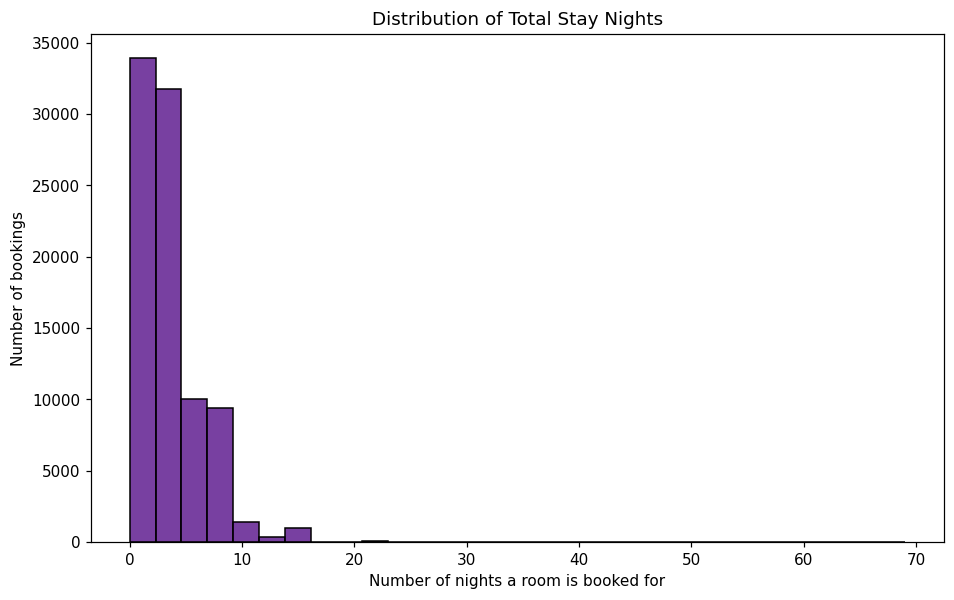

In [375]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['total_stay_nights'], bins=30, color='indigo')
plt.title('Distribution of Total Stay Nights')
plt.xlabel('Number of nights a room is booked for')
plt.ylabel('Number of bookings')
plt.show()

**Distribution of Average Daily Rate (ADR)**

This boxplot displays the distribution of the `adr` (Average Daily Rate). It shows the median, quartiles, and potential outliers in the pricing of the bookings. The presence of outliers at the higher end indicates some bookings have significantly higher daily rates, which were capped earlier during cleaning.

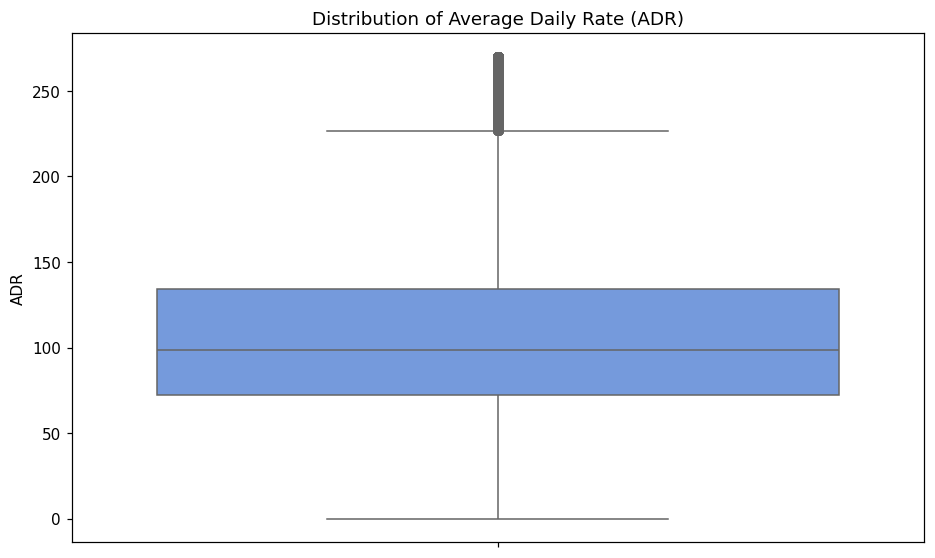

In [376]:
plt.figure(figsize=(10, 6))
sns.boxplot(y=df['adr'], color='cornflowerblue') # Changed color here
plt.title('Distribution of Average Daily Rate (ADR)')
plt.ylabel('ADR')
plt.show()

**10. Exploratory Data Analysis (on the cleaned data)**

This EDA is scoped to the stakeholder question from Section 9. Univariate
checks establish distribution shape, bivariate checks test candidate
predictors against the target, and the multivariate check looks for
interaction/confounding before Stage 2 modelling.

In [377]:
cancel_counts = df["is_canceled"].value_counts()
cancel_pct = df["is_canceled"].value_counts(normalize=True)
print(cancel_counts)
print(cancel_pct.round(3))

is_canceled
0    63567
1    24565
Name: count, dtype: int64
is_canceled
0    0.721
1    0.279
Name: proportion, dtype: float64


**Interpretation:** After cleaning, the target is **~28% cancelled vs 72%
kept** — moderately imbalanced. Stage 2 modelling should use metrics beyond
raw accuracy (recall/precision on the cancelled class, ROC-AUC) and consider
class weighting.

In [378]:
numeric_predictors = ["lead_time", "adr", "previous_cancellations", "total_of_special_requests", "booking_changes"]

summary = df.groupby("is_canceled")[numeric_predictors].mean().T
summary.columns = ["Kept (0)", "Cancelled (1)"]
summary["difference"] = summary["Cancelled (1)"] - summary["Kept (0)"]
summary.round(2)

,Kept (0),Cancelled (1),difference
lead_time,73.07,111.07,38.00
adr,102.35,117.43,15.08
previous_cancellations,0.02,0.07,0.05
total_of_special_requests,0.76,0.53,-0.23
booking_changes,0.31,0.16,-0.15


In [379]:
correlations = df[numeric_predictors + ["is_canceled"]].corr(numeric_only=True)["is_canceled"].drop("is_canceled")
correlations.sort_values(key=abs, ascending=False).round(3)

,is_canceled
lead_time,0.170
adr,0.131
total_of_special_requests,-0.126
booking_changes,-0.095
previous_cancellations,0.055


**Interpretation:** `lead_time` remains the strongest numeric signal
(**r ≈ 0.17**) — bookings made further in advance are more likely to fall
through. `adr` now shows a small positive association (**r ≈ 0.13**), a
shift from the raw-data EDA, most likely because cleaning removed a large
block of duplicated `Non Refund` bookings that were distorting the raw
correlations. `total_of_special_requests` (**r ≈ -0.13**) and
`booking_changes` (**r ≈ -0.10**) are negatively associated — guests who
engage more with their booking are less likely to cancel. All correlations
are modest, meaning no single variable is sufficient alone — a multivariate
model is justified.

**11. Categorical predictors vs cancellation**

In [380]:
for col in ["deposit_type", "hotel", "market_segment", "customer_type"]:
    print(f"--- Cancellation rate by {col} ---")
    print(df.groupby(col)["is_canceled"].agg(rate="mean", n="count").sort_values("rate", ascending=False))
    print()

--- Cancellation rate by deposit_type ---
                  rate      n
deposit_type                 
Non Refund    0.960000   1375
No Deposit    0.267969  86648
Refundable    0.238532    109

--- Cancellation rate by hotel ---
                  rate      n
hotel                        
City Hotel    0.305389  53977
Resort Hotel  0.236598  34155

--- Cancellation rate by market_segment ---
                    rate      n
market_segment                 
Undefined       1.000000      3
Unknown         0.429688    128
Online TA       0.354302  51648
Groups          0.301139   5270
Aviation        0.199115    226
Offline TA/TO   0.156952  14119
Direct          0.147963  11807
Complementary   0.125000    696
Corporate       0.124203   4235

--- Cancellation rate by customer_type ---
                     rate      n
customer_type                   
Unknown          0.388158    152
Transient        0.304859  72263
Contract         0.166614   3151
Transient-Party  0.157825  12026
Group        

### **Correlation Statistics for Numeric Predictors vs. Cancellation**

This section calculates different types of correlation coefficients (Pearson, Spearman, Kendall) between numerical features and the `is_canceled` target variable. These statistics help to quantify the strength and direction of linear and monotonic relationships. For example, a positive Pearson correlation for `lead_time` suggests that as lead time increases, the likelihood of cancellation also tends to increase.

In [381]:
import scipy.stats as stats
from scipy.stats import chi2_contingency
import numpy as np

# Numeric Predictors
numeric_predictors = ["lead_time", "adr", "previous_cancellations", "total_of_special_requests", "booking_changes"]

print("\n--- Correlation Statistics for Numeric Predictors vs. is_canceled ---")
for col in numeric_predictors:
    print(f"\nFeature: {col}")
    print(f"  Pearson: {df[col].corr(df['is_canceled'], method='pearson'):.3f}")
    print(f"  Spearman: {df[col].corr(df['is_canceled'], method='spearman'):.3f}")
    print(f"  Kendall: {df[col].corr(df['is_canceled'], method='kendall'):.3f}")


--- Correlation Statistics for Numeric Predictors vs. is_canceled ---

Feature: lead_time
  Pearson: 0.170
  Spearman: 0.229
  Kendall: 0.188

Feature: adr
  Pearson: 0.131
  Spearman: 0.139
  Kendall: 0.114

Feature: previous_cancellations
  Pearson: 0.055
  Spearman: 0.134
  Kendall: 0.134

Feature: total_of_special_requests
  Pearson: -0.126
  Spearman: -0.134
  Kendall: -0.127

Feature: booking_changes
  Pearson: -0.095
  Spearman: -0.126
  Kendall: -0.124


<Figure size 1100x660 with 0 Axes>

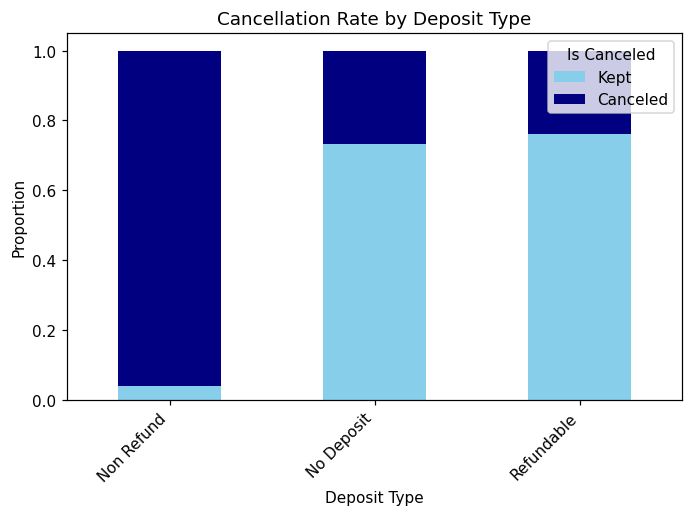

<Figure size 1100x660 with 0 Axes>

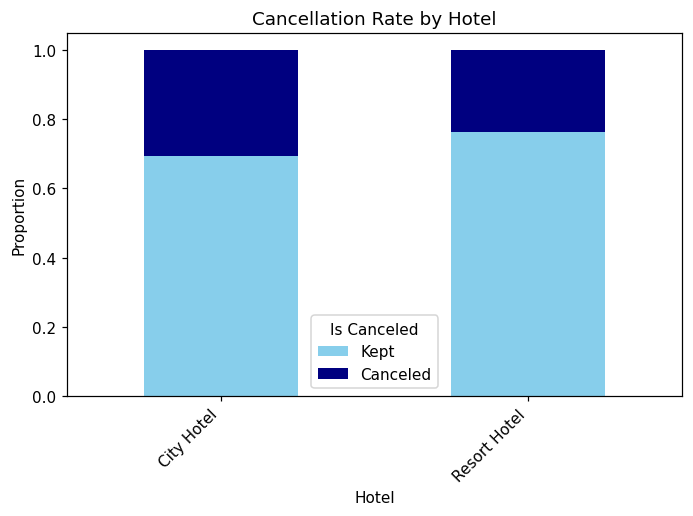

<Figure size 1100x660 with 0 Axes>

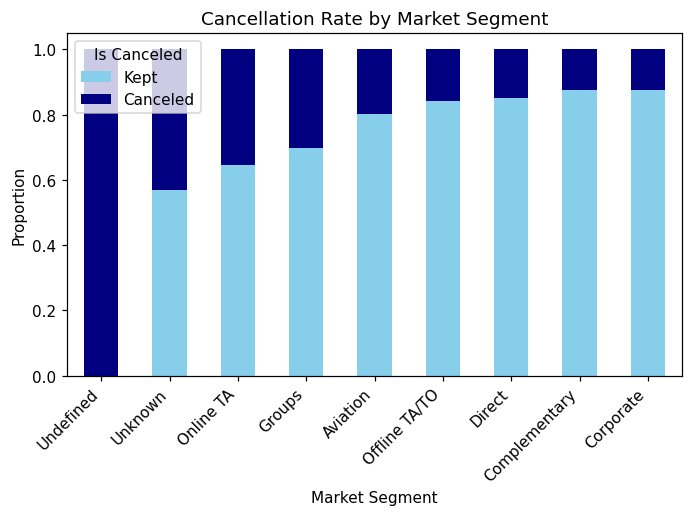

<Figure size 1100x660 with 0 Axes>

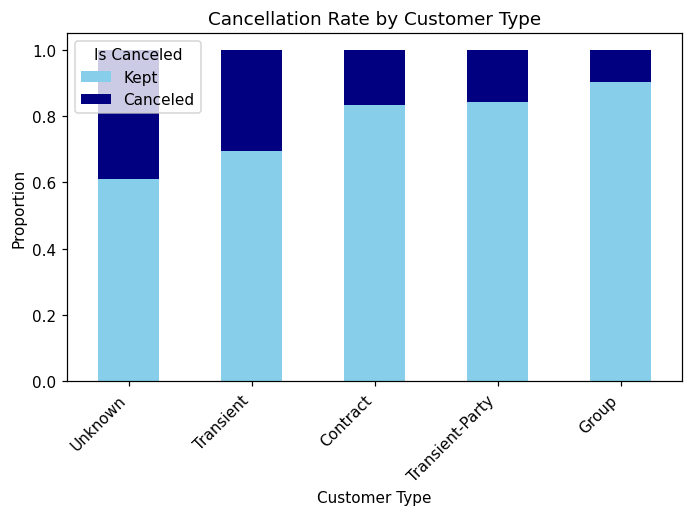

In [382]:
import matplotlib.pyplot as plt
import seaborn as sns

categorical_cols = ["deposit_type", "hotel", "market_segment", "customer_type"]

for col in categorical_cols:
    plt.figure(figsize=(10, 6))
    # Calculate the proportion of canceled vs. not canceled for each category
    # Unstacking moves the 'is_canceled' levels to columns for easy plotting
    plot_data = df.groupby(col)["is_canceled"].value_counts(normalize=True).unstack()

    # Ensure both 0 (kept) and 1 (canceled) columns exist, fill with 0 if not
    if 0 not in plot_data.columns:
        plot_data[0] = 0
    if 1 not in plot_data.columns:
        plot_data[1] = 0

    # Sort by cancellation rate for better readability
    plot_data = plot_data.sort_values(by=1, ascending=False)

    # Plotting as a stacked bar chart
    plot_data.plot(kind='bar', stacked=True, color={0: 'skyblue', 1: 'navy'})

    plt.title(f'Cancellation Rate by {col.replace("_", " ").title()}')
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel('Proportion')
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='Is Canceled', labels=['Kept', 'Canceled'])
    plt.tight_layout()
    plt.show()


### **Cancellation Rate by Categorical Features**

These stacked bar charts illustrate the cancellation rate across different categories for selected categorical features like `deposit_type`, `hotel`, `market_segment`, and `customer_type`. Each bar represents a category, and the colored segments within the bar show the proportion of kept (0) versus canceled (1) bookings. This visualization helps to quickly identify which categories are associated with higher or lower cancellation probabilities. For instance, a category with a predominantly 'Canceled' segment indicates a high cancellation risk.

### **Conclusion based on the correlation statistics:**

1. **Deposit Type is a Major Predictor**: Bookings with a 'Non Refund' deposit type have an extremely high cancellation rate (around 96%), indicating this is a very strong signal for predicting cancellations. 'No Deposit' and 'Refundable' bookings have significantly lower, more similar cancellation rates.

2. **Lead Time Matters**: Longer lead_time (bookings made further in advance) shows a consistent positive correlation with is_canceled across Pearson, Spearman, and Kendall methods. This suggests that the more time passes between booking and arrival, the higher the likelihood of cancellation.

3. **ADR and Cancellation**: Higher adr (Average Daily Rate) has a positive correlation with is_canceled. This is further supported by the observation that the average ADR for cancelled bookings is higher than for kept bookings. This could imply that more expensive bookings are more prone to cancellation.

4. **Customer Engagement Reduces Cancellation**: Variables like total_of_special_requests and booking_changes show a negative correlation with is_canceled. This implies that guests who make special requests or modify their bookings are less likely to cancel, possibly indicating higher commitment or engagement with their reservation.

5. **Hotel Type Influences Cancellation**: 'City Hotels' generally experience a higher cancellation rate than 'Resort Hotels'. This could be due to differences in guest demographics, booking purposes, or flexibility offered.

6. **Market Segment Variability**: Certain market segments, like 'Online TA' and 'Unknown' or 'Undefined' categories, exhibit higher cancellation rates, while 'Direct', 'Corporate', and 'Offline TA/TO' segments have lower cancellation rates. This highlights the importance of understanding the booking source.

7. **Customer Type Insights**: 'Transient' and 'Unknown' customer types show higher cancellation tendencies, whereas 'Contract', 'Transient-Party', and 'Group' bookings are less likely to be cancelled.

8. **Distribution of Stay Nights**: The histogram of total_stay_nights reveals that the vast majority of bookings are for very short durations (1-3 nights), with a rapid decrease in frequency for longer stays. While this plot didn't directly correlate with is_canceled, it gives us a good understanding of the typical booking patterns.


In summary, deposit type, lead time, ADR, market segment, customer type, and customer engagement (special requests, booking changes) are all important factors to consider when building a model to predict booking cancellations. The overall cancellation rate is about 28%, meaning there's a significant portion of bookings that don't materialize, impacting hotel revenue.